In [ ]:
import json
import pandas as pd
from plotly.offline import get_plotlyjs

df = pd.read_csv("Merged_cleaned_daily_data.csv", low_memory=False)
df["day"] = pd.to_datetime(df["day"])
df["is_Khamsin_label"] = df["is_Khamsin_season"].map({0: "Non-Khamsin", 1: "Khamsin"})

cols = ["station_id", "day", "season", "is_Khamsin_label",
        "pm2_5_corrected", "pm10", "nitrogen_dioxide", "sulphur_dioxide",
        "wind_speed_10m_mean", "relative_humidity_2m_mean", "temperature_2m_mean",
        "surface_pressure_mean", "precipitation_mean"]
d = df[cols].copy()
months = sorted(d["day"].dt.strftime("%Y-%m").unique().tolist())
d["day"] = d["day"].dt.strftime("%Y-%m-%d")
d = d.round(3).astype(object).where(d.notna(), None)
data_json = json.dumps(d.to_dict("records"))

# ---------- 2. HTML template (all charts are redrawn by JS when a filter changes) ----------
TEMPLATE = r"""<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Cairo Air Quality & Meteorological Analytics Dashboard</title>
<style>
 body{font-family:Arial,sans-serif;background:#f8fafc;margin:0;padding:24px;color:#1e293b}
 .wrap{max-width:1350px;margin:0 auto}
 h1{font-size:22px;margin:0 0 14px}
 .bar{display:flex;gap:18px;flex-wrap:wrap;align-items:center;background:#fff;border:1px solid #e2e8f0;
      border-radius:12px;padding:14px 18px;margin-bottom:18px;position:sticky;top:0;z-index:5}
 .bar label{font-size:13px;font-weight:bold}
 .bar select{margin-left:6px;padding:5px 8px;font-size:14px}
 #info{margin-left:auto;font-size:13px;color:#475569}
 h3{margin:4px 8px 2px;font-size:16px}
 .d{margin:0 8px 6px;font-size:12.5px;color:#475569}
 .card{background:#fff;border:1px solid #e2e8f0;border-radius:12px;padding:12px;margin-bottom:18px}
 .row{display:grid;grid-template-columns:1fr 1fr;gap:18px}
 @media(max-width:900px){.row{grid-template-columns:1fr}}
</style></head><body><div class="wrap">
<h1>Cairo Air Quality & Meteorological Analytics Dashboard</h1>
<div class="bar">
 <label>District <select id="dist"></select></label>
 <label>From <select id="from"></select></label>
 <label>To <select id="to"></select></label>
 <span id="info"></span>
</div>
<div class="row"><div class="card"><h3>PM2.5 vs Wind Speed (Dispersion Effect)</h3><p class="d">Each dot is one station-day, coloured by district. Higher wind speed generally goes with lower PM2.5, because wind disperses pollutants.</p><div id="sc1"></div></div><div class="card"><h3>NO2 vs Temperature</h3><p class="d">Each dot is one station-day, coloured by district. NO2 tends to be higher on colder days and lower on hotter days.</p><div id="sc2"></div></div></div>
<div class="row"><div class="card"><h3>PM2.5 across Seasons</h3><p class="d">Daily PM2.5 distribution per season. Box = middle 50% of days, line = median, dots = outlier days.</p><div id="bx1"></div></div><div class="card"><h3>PM2.5: Khamsin vs Non-Khamsin</h3><p class="d">Daily PM2.5 during the Khamsin season (Mar-May) compared with the rest of the year.</p><div id="bx2"></div></div></div>
<div class="card"><h3>Spearman Correlation Matrix: Pollutants vs Weather</h3><p class="d">Rank correlation from -1 to +1 for the selected district and dates. Red = rise together, blue = move in opposite directions.</p><div id="heat"></div></div>
</div>
<script>__PLOTLY__</script>
<script>
const DATA = __DATA__;
const MONTHS = __MONTHS__;
const DIST = [...new Set(DATA.map(r => r.station_id))].sort();
const COL = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd'];
const nice = s => s.replace(/_/g,' ').replace(/\b\w/g, c => c.toUpperCase());
const $ = id => document.getElementById(id);

// ---- Spearman (pairwise-complete, average ranks for ties; same as pandas) ----
function rank(a){
  const o = a.map((v,i)=>[v,i]).sort((x,y)=>x[0]-y[0]), r = new Array(a.length);
  for(let i=0,j;i<o.length;i=j+1){ j=i; while(j+1<o.length && o[j+1][0]===o[i][0]) j++;
    for(let k=i;k<=j;k++) r[o[k][1]] = (i+j)/2+1; }
  return r;
}
function pearson(x,y){
  const n=x.length; if(n<3) return null;
  const mx=x.reduce((a,b)=>a+b,0)/n, my=y.reduce((a,b)=>a+b,0)/n;
  let sxy=0,sxx=0,syy=0;
  for(let i=0;i<n;i++){ sxy+=(x[i]-mx)*(y[i]-my); sxx+=(x[i]-mx)**2; syy+=(y[i]-my)**2; }
  return (sxx&&syy) ? sxy/Math.sqrt(sxx*syy) : null;
}
function spearman(rows,a,b){
  const p = rows.filter(r => r[a]!==null && r[b]!==null);
  const v = pearson(rank(p.map(r=>r[a])), rank(p.map(r=>r[b])));
  return v===null ? null : Math.round(v*100)/100;
}

// ---- controls ----
$('dist').innerHTML = '<option value="all">All Districts</option>' + DIST.map(d=>`<option value="${d}">${nice(d)}</option>`).join('');
$('from').innerHTML = $('to').innerHTML = MONTHS.map(m=>`<option value="${m}">${m}</option>`).join('');
$('from').value = MONTHS[0]; $('to').value = MONTHS[MONTHS.length-1];

function filtered(){
  let a=$('from').value, b=$('to').value; if(a>b){ [a,b]=[b,a]; }
  const d=$('dist').value;
  return DATA.filter(r => (d==='all'||r.station_id===d) && r.day.slice(0,7)>=a && r.day.slice(0,7)<=b);
}

const LAY = {margin:{t:20,b:55,l:65,r:20}, height:400};
const T = t => ({title:{text:t}});
function draw(){
  const rows = filtered();
  $('info').textContent = rows.length + ' station-days selected';
  const dl = [...new Set(rows.map(r=>r.station_id))].sort();
  const sc = (x,y) => dl.map(d => { const s = rows.filter(r=>r.station_id===d);
    return {type:'scatter', mode:'markers', name:nice(d), x:s.map(r=>r[x]), y:s.map(r=>r[y]),
            marker:{size:6, opacity:.65, color:COL[DIST.indexOf(d)]}}; });
  Plotly.react('sc1', sc('wind_speed_10m_mean','pm2_5_corrected'),
    {...LAY, showlegend:true, xaxis:T('Wind speed 10m mean (m/s)'), yaxis:T('PM2.5 corrected (µg/m³)')});
  Plotly.react('sc2', sc('temperature_2m_mean','nitrogen_dioxide'),
    {...LAY, showlegend:true, xaxis:T('Temperature 2m mean (°C)'), yaxis:T('NO2 (µg/m³)')});

  const box = (key, order, colors) => order.map((k,i) => ({type:'box', name:k[0].toUpperCase()+k.slice(1),
    y:rows.filter(r=>r[key]===k).map(r=>r.pm2_5_corrected), marker:{color:colors[i]}, boxpoints:'outliers'}));
  Plotly.react('bx1', box('season',['winter','spring','summer','autumn'],['#4575b4','#74add1','#f46d43','#fdae61']),
    {...LAY, showlegend:false, xaxis:T('Season'), yaxis:T('PM2.5 corrected (µg/m³)')});
  Plotly.react('bx2', box('is_Khamsin_label',['Non-Khamsin','Khamsin'],['#2b83ba','#d7191c']),
    {...LAY, showlegend:false, xaxis:T('Period'), yaxis:T('PM2.5 corrected (µg/m³)')});

  const keys=['pm2_5_corrected','pm10','nitrogen_dioxide','sulphur_dioxide','wind_speed_10m_mean','relative_humidity_2m_mean','temperature_2m_mean','surface_pressure_mean','precipitation_mean'];
  const lab=['PM2.5','PM10','NO2','SO2','Wind Speed','Humidity','Temperature','Pressure','Precipitation'];
  const z = keys.map(a => keys.map(b => spearman(rows,a,b)));
  Plotly.react('heat', [{type:'heatmap', x:lab, y:lab, z:z, text:z, texttemplate:'%{text}', zmin:-1, zmax:1,
      colorscale:'RdBu', reversescale:true, colorbar:{title:{text:'Spearman r'}}}],
    {height:620, margin:{t:20,b:90,l:100,r:40}, yaxis:{autorange:'reversed'}});
}
['dist','from','to'].forEach(id => $(id).addEventListener('change', draw));
draw();
</script></body></html>"""

html = (TEMPLATE.replace("__PLOTLY__", get_plotlyjs())
                .replace("__DATA__", data_json)
                .replace("__MONTHS__", json.dumps(months)))

with open("cairo_air_quality_dashboard.html", "w", encoding="utf-8") as f:
    f.write(html)
print("Dashboard saved: cairo_air_quality_dashboard.html  (works offline)")


Dashboard saved: cairo_air_quality_dashboard.html  (works offline)


C:\Users\usifa\AppData\Local\Temp\ipykernel_13660\2873472618.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["is_Khamsin_label"] = df["is_Khamsin_season"].map({0: "Non-Khamsin", 1: "Khamsin"})


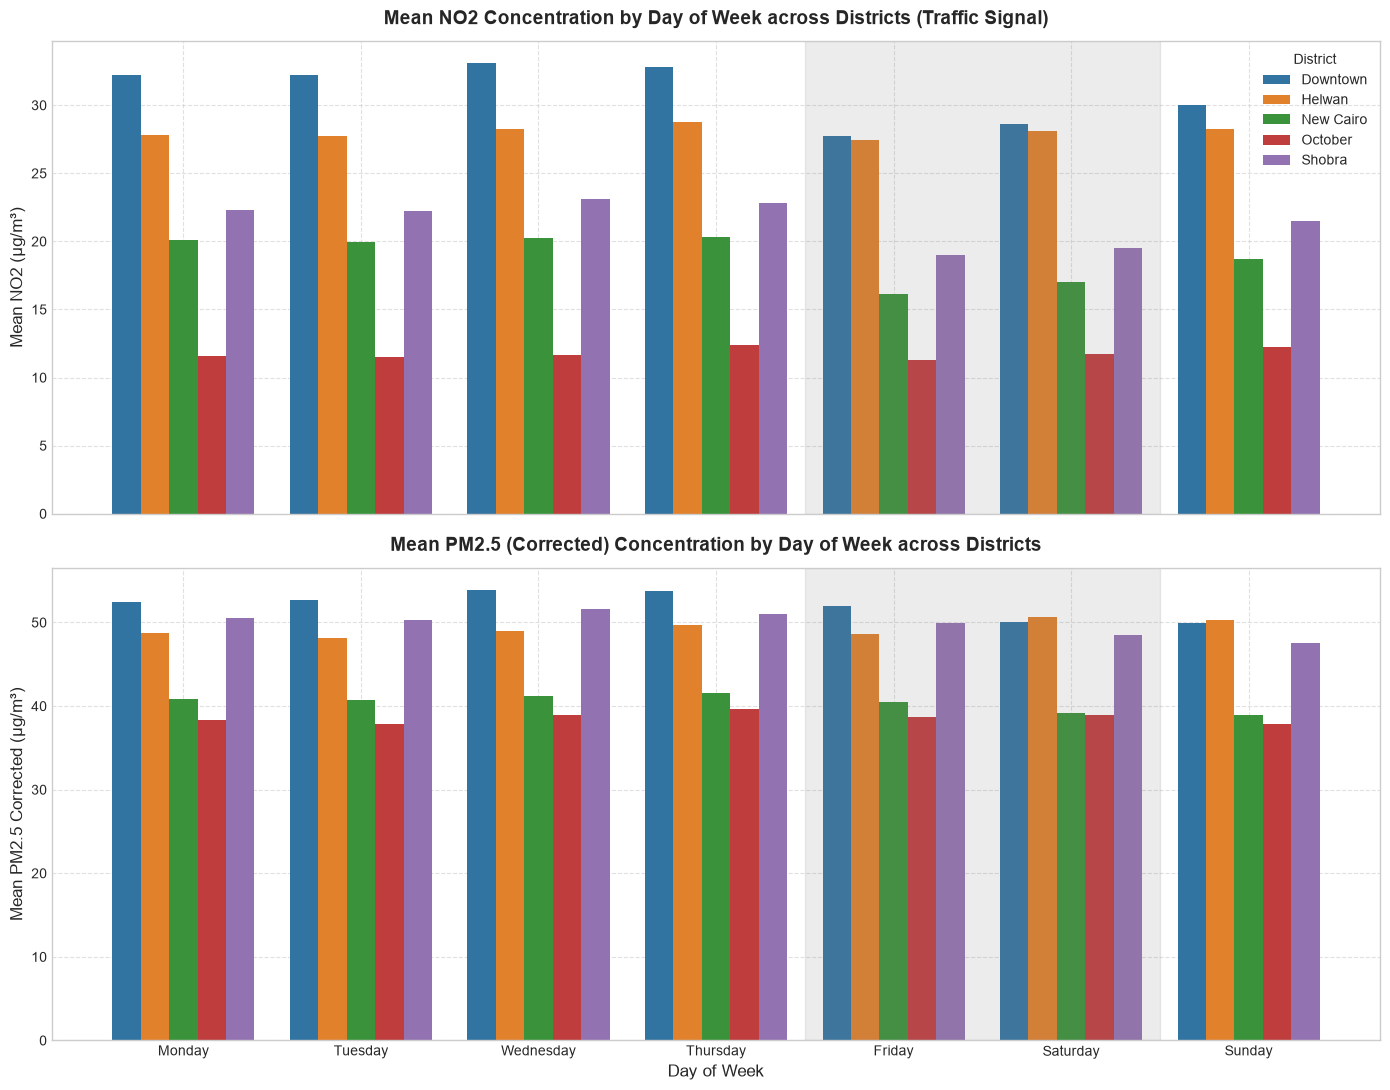

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Merged_cleaned_daily_data.csv")

days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

weekly_summary = df.groupby(['station_id', 'day_of_week'])[['pm2_5_corrected', 'nitrogen_dioxide']].mean().reset_index()
weekly_summary['day_of_week'] = pd.Categorical(weekly_summary['day_of_week'], categories=days_order, ordered=True)
weekly_summary['District'] = weekly_summary['station_id'].str.replace('_', ' ').str.title()
weekly_summary = weekly_summary.sort_values(['station_id', 'day_of_week'])

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 1, figsize=(14, 11), sharex=True)
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

sns.barplot(data=weekly_summary, x='day_of_week', y='nitrogen_dioxide', hue='District', palette=palette, ax=axes[0])
axes[0].set_title("Mean NO2 Concentration by Day of Week across Districts (Traffic Signal)", fontsize=14, fontweight='bold', pad=12)
axes[0].set_ylabel("Mean NO2 (µg/m³)", fontsize=12)
axes[0].set_xlabel("")
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(title="District", loc='upper right')
axes[0].axvspan(3.5, 5.5, color='gray', alpha=0.15)  

sns.barplot(data=weekly_summary, x='day_of_week', y='pm2_5_corrected', hue='District', palette=palette, ax=axes[1])
axes[1].set_title("Mean PM2.5 (Corrected) Concentration by Day of Week across Districts", fontsize=14, fontweight='bold', pad=12)
axes[1].set_ylabel("Mean PM2.5 Corrected (µg/m³)", fontsize=12)
axes[1].set_xlabel("Day of Week", fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend().remove()
axes[1].axvspan(3.5, 5.5, color='gray', alpha=0.15)

plt.tight_layout()
plt.savefig("weekday_weekend_pollution_comparison.png", dpi=300)
plt.show()

summary_pivot = weekly_summary.pivot(index='day_of_week', columns='District', values=['nitrogen_dioxide', 'pm2_5_corrected']).round(2)
summary_pivot.to_csv("weekly_pollution_summary_table.csv")

In [ ]:
import pandas as pd

df = pd.read_csv("Merged_cleaned_daily_data_task3.csv", low_memory=False)
df["day"] = pd.to_datetime(df["day"])
df = df.sort_values(["station_id", "day"]).reset_index(drop=True)

for col in [c for c in df.columns if "_roll_avg_" in c]:
    base, w = col.split("_roll_avg_")
    df[col] = df.groupby("station_id")[base].transform(
        lambda s: s.shift(1).rolling(int(w[:-1]), min_periods=1).mean())

to_drop = [
    "pm10","carbon_monoxide","nitrogen_dioxide","sulphur_dioxide","ozone",
    "s5p_co_col","s5p_so2_col","s5p_co_col_gap_days","s5p_co_col_is_observed",
    "s5p_so2_col_gap_days","s5p_so2_col_is_observed",
    "pm10_min","pm10_max","pm10_std","pm10_var",
    "carbon_monoxide_min","carbon_monoxide_max","carbon_monoxide_std","carbon_monoxide_var",
    "sulphur_dioxide_min","sulphur_dioxide_max","sulphur_dioxide_std","sulphur_dioxide_var",
    "ozone_min","ozone_max","ozone_std","ozone_var",
    "nitrogen_dioxide_min","nitrogen_dioxide_max","nitrogen_dioxide_std","nitrogen_dioxide_var",
    "pm2_5_corrected_min","pm2_5_corrected_max","pm2_5_corrected_std","pm2_5_corrected_var",
]
df = df.drop(columns=to_drop + ["Unnamed: 0"])

df.to_parquet("daily_features_v2.parquet", index=False)

chk = pd.read_parquet("daily_features_v2.parquet")
rec = 3*chk.pm2_5_corrected_roll_avg_3d - chk.pm2_5_corrected_lag_1d - chk.pm2_5_corrected_lag_2d
print(chk.shape)                               
print((rec - chk.pm2_5_corrected).abs().max())  

(5480, 105)
126.7397499999999
